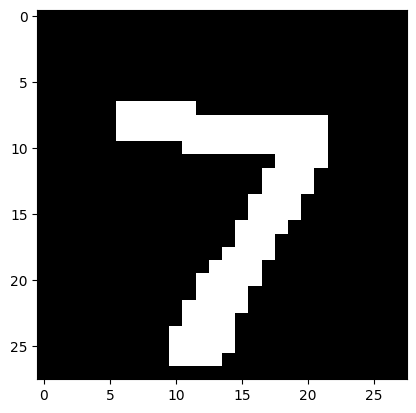

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import os


m_x = np.loadtxt('mnist_x.txt', delimiter=' ')
m_y = np.loadtxt('mnist_y.txt')

data = np.reshape(np.array(m_x[0],dtype = int), (28, 28))
plt.figure()
plt.imshow(data, cmap='gray')


ration = 0.8
split = int(len(m_x) * ration)

np.random.seed(0)
idx = np.random.permutation(len(m_x))
m_x =m_x[idx]
m_y = m_y[idx]
x_train, x_test = m_x[:split], m_x[split:]
y_train, y_test = m_y[:split], m_y[split:]

In [18]:
def distance(a, b):
    return np.sqrt(np.sum((a - b) ** 2))


In [19]:
class KNN:
    def __init__(self,k, label_num):
        self.k = k
        self.label_num =label_num

    def fit(self, x_train, y_train):
        self.x_train = x_train
        self.y_train = y_train 

    def get_knn_indices(self,x):
        dis =list(map(lambda a: distance(a, x), self.x_train))
        knn_indices = np.argsort(dis)
        knn_indices = knn_indices[:self.k]
        return knn_indices

    def get_label(self, x):
        knn_indices = self.get_knn_indices(x)
        label_statistics = np.zeros(shape=[self.label_num])
        for index in knn_indices:
            label_statistics[int(self.y_train[index])] += 1
        return np.argmax(label_statistics)

    def predict(self,x_test):
        predicted_test_labels = np.zeros(shape=[len(x_test)], dtype=int)
        for i,x in enumerate(x_test):
            predicted_test_labels[i] = self.get_label(x)
        return predicted_test_labels

In [20]:
for k in range(1, 10):
    knn = KNN(k, label_num=10)
    knn.fit(x_train, y_train)
    predicted_labels = knn.predict(x_test)
    accuracy = np.mean(predicted_labels == y_test)
    print(f'k={k}, accuracy={accuracy:.4f}')

k=1, accuracy=0.8800
k=2, accuracy=0.8800
k=3, accuracy=0.8800
k=4, accuracy=0.8700
k=5, accuracy=0.8850
k=6, accuracy=0.8850
k=7, accuracy=0.8800
k=8, accuracy=0.8750
k=9, accuracy=0.8700


数据集大小： 200


Text(0.5, 1.0, 'Gaussian Data')

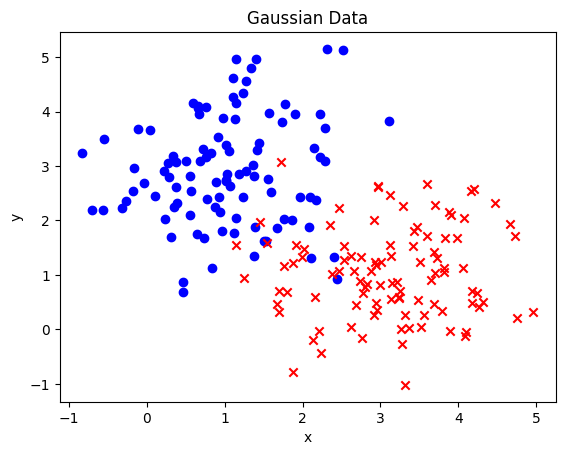

In [21]:
from sklearn.neighbors import KNeighborsClassifier #sklearn中的KNN分类器
from matplotlib.colors import ListedColormap
import numpy as np
import matplotlib.pyplot as plt


#读入高斯数据集
data = np.loadtxt('gauss.csv',delimiter=',')
x_train = data[:,:2]
y_train = data[:,2]
print('数据集大小：',len(x_train))

#可视化
plt.figure()
plt.scatter(x_train[y_train==0,0],x_train[y_train==0,1],c='blue',marker='o')
plt.scatter(x_train[y_train==1,0],x_train[y_train==1,1],c='red',marker='x')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Gaussian Data')

In [22]:
#设置步长
step = 0.02
#设置网格边界
x_min, x_max = np.min(x_train[:, 0]) - 1, np.max(x_train[:, 0]) + 1
y_min, y_max = np.min(x_train[:, 1]) - 1, np.max(x_train[:, 1]) + 1
#构造网格
xx, yy = np.meshgrid(np.arange(x_min, x_max, step), np.arange(y_min, y_max, step))
grid_data = np.concatenate((xx.reshape(-1, 1), yy.reshape(-1, 1)), axis=1)

(409, 390)
(409, 390)
(159510, 2)
(409, 390)
(409, 390)
(159510, 2)
(409, 390)
(409, 390)
(159510, 2)
(409, 390)
(409, 390)
(159510, 2)
(409, 390)
(409, 390)
(159510, 2)


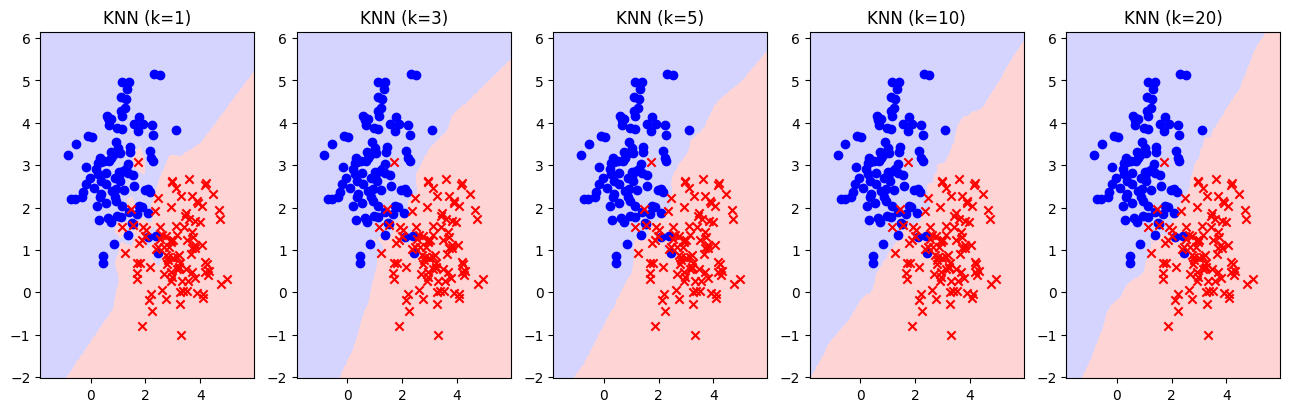

In [23]:
fig = plt.figure(figsize=(16,4.5))
#k值
ks=[1,3,5,10,20]
cmap_light = ListedColormap(['#AAAAFF', '#FFAAAA'])

for i, k in enumerate(ks):
    #创建KNN分类器
    knn = KNeighborsClassifier(n_neighbors=k)
    #训练模型
    knn.fit(x_train, y_train)
    #预测网格数据
    Z = knn.predict(grid_data)
    Z = Z.reshape(xx.shape)

    print(xx.shape)
    print(yy.shape)
    print(grid_data.shape)
    plt.subplot(1, 5, i + 1)
    plt.pcolormesh(xx, yy, Z, cmap=cmap_light,alpha=0.5)
    plt.scatter(x_train[y_train==0,0],x_train[y_train==0,1],c='blue',marker='o')
    plt.scatter(x_train[y_train==1,0],x_train[y_train==1,1],c='red',marker='x')
    plt.title(f'KNN (k={k})')

In [37]:
from skimage import io
from skimage.color import rgb2lab,lab2rgb
from sklearn.neighbors import KNeighborsRegressor
import os
import numpy as np
import matplotlib.pyplot as plt

path = 'style_transfer'

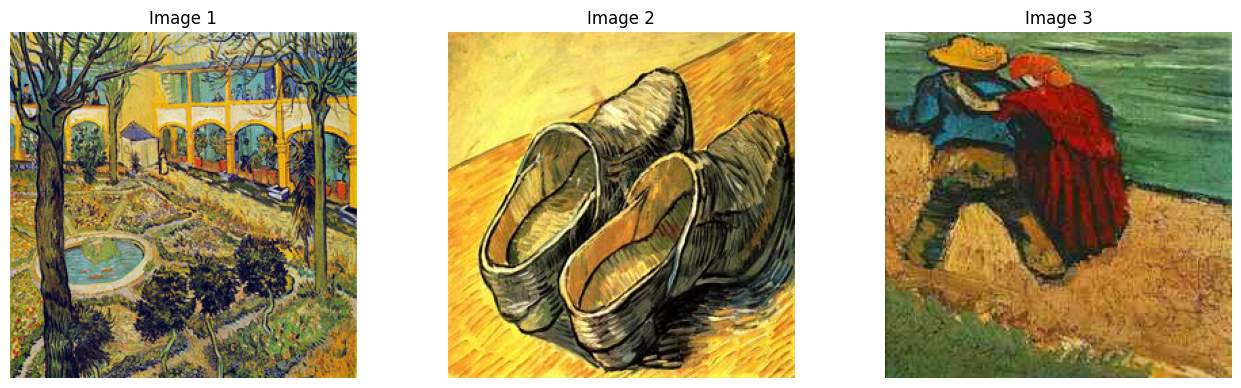

In [38]:
data_dir = os.path.join( path,'vangogh')
fig = plt.figure(figsize=(16,4.5))
for i, file in enumerate(np.sort(os.listdir(data_dir))[:3]):
    img = io.imread(os.path.join(data_dir, file))
    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.axis('off')
    plt.title(f'Image {i+1}')

In [39]:
#block_size表示向外扩展的层数
block_size = 1

def read_style_image(file_name, size=block_size):
    #读入风格图片
    #X是3*3的灰度值，Y是色彩值
    #读取图像文件，设置图像宽为w，高为H，得到W*H*3的RGB矩阵
    img = io.imread(file_name)
    fig = plt.figure(figsize=(16,4.5))
    plt.imshow(img)
    plt.show()

    #将RGB图像转换为Lab颜色空间矩阵，三维分别是L，A，B
    img_lab = rgb2lab(img)
    # 取出图像的高度、宽度
    w,h= img.shape[:2]

    X=[]
    Y=[]
    #枚举图像的每个像素点
    for x in range(size,w-size):
        for y in range(size,h-size):
            #保存所有窗口
            X.append(img_lab[x-size:x+size+1,\
                y-size:y+size+1,0].flatten())
            #保存窗口对应的色彩值a和b
            Y.append(img_lab[x,y,1:])
    return X, Y

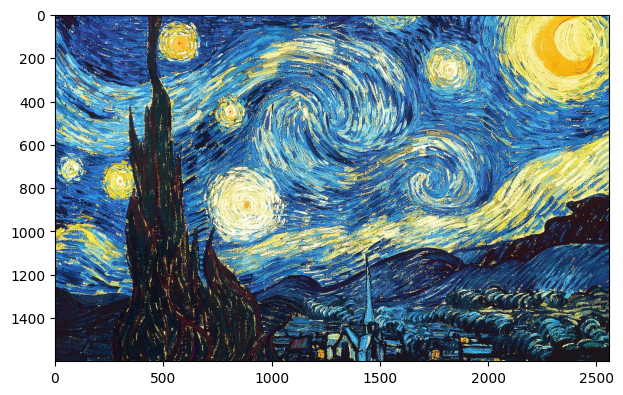

,n_neighbors,4
,weights,'distance'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [40]:
X,Y = read_style_image(os.path.join(path,'style.jpg')) # 建立映射

# weights='distance'表示邻居的权重与距离成反比
knn = KNeighborsRegressor(n_neighbors=4, weights='distance')
knn.fit(X, Y)

In [43]:
def rebuild(img,size=block_size):
    #重建图像
    fig = plt.figure()
    plt.imshow(img)
    plt.show()

    # 将图像转换成LAB表示
    img_lab = rgb2lab(img)
    w,h= img.shape[:2]

    #初始化输出图像对应的矩阵
    photo = np.zeros((w,h,3))
    #枚举图像的每个像素点，保存所有窗口
    print('重建图像中...')
    X=[]
    for x in range(size,w-size):
        for y in range(size,h-size):
            #得到中心点对应的窗口
            window = img_lab[x-size:x+size+1,\
                y-size:y+size+1,0].flatten()
            X.append(window)

    X = np.array(X)
    #使用KNN预测色彩值
    print('预测色彩值中...')
    pred_ab = knn.predict(X).reshape(w-2*size,h-2*size,-1)
    #设置输出图像
    print('设置输出图像中...')
    photo[:,:,0] = img_lab[:,:,0]
    photo[size:w-size,size:h-size,1:] = pred_ab
    print('裁剪图像中...')

#由于最外面size无法构造窗口，因此直接裁掉
    print('裁剪图像中...')
    photo = photo[size:w-size,size:h-size,:]
    return photo

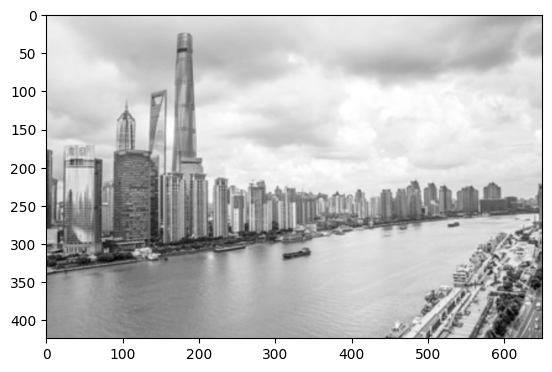

重建图像中...
预测色彩值中...
设置输出图像中...
裁剪图像中...
裁剪图像中...


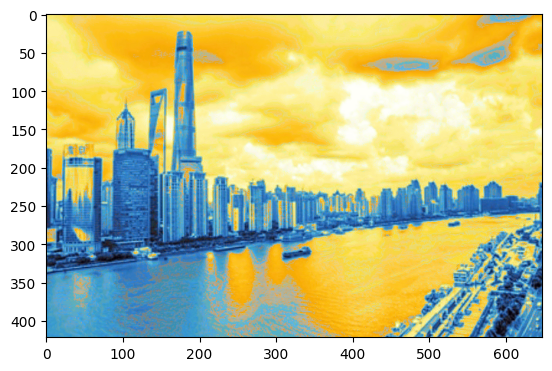

In [44]:
content = io.imread(os.path.join(path,'input.jpg'))
new_photo = rebuild(content)

new_photo= lab2rgb(new_photo)

fig = plt.figure()
plt.imshow(new_photo)
plt.show()